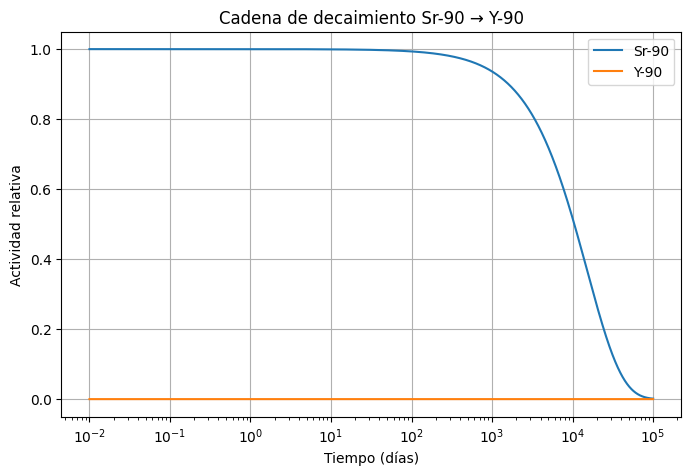

In [ ]:
#ejercicio 1
import numpy as np
import matplotlib.pyplot as plt

# Vidas medias
t12_Sr = 28.78 * 365      # años -> días
t12_Y = 2.67              # días

# Constantes de decaimiento
lambda_Sr = np.log(2) / t12_Sr
lambda_Y = np.log(2) / t12_Y

t_max = 1e5   # días
N = 200000
t = np.logspace(-2, np.log10(t_max), N)
dt = np.diff(t)

N_Sr = np.zeros(N)
N_Y = np.zeros(N)

N_Sr[0] = 1.0   # actividad relativa inicial
N_Y[0] = 0.0

# Método de Euler
for i in range(N - 1):
    dN_Sr = -lambda_Sr * N_Sr[i]
    dN_Y = lambda_Sr * N_Sr[i] - lambda_Y * N_Y[i]

    N_Sr[i + 1] = N_Sr[i] + dN_Sr * dt[i]
    N_Y[i + 1] = N_Y[i] + dN_Y * dt[i]

plt.figure(figsize=(8, 5))
plt.plot(t, N_Sr, label='Sr-90')
plt.plot(t, N_Y, label='Y-90')
plt.xscale('log')
plt.xlabel('Tiempo (días)')
plt.ylabel('Actividad relativa')
plt.title('Cadena de decaimiento Sr-90 → Y-90')
plt.legend()
plt.grid(True)
plt.show()

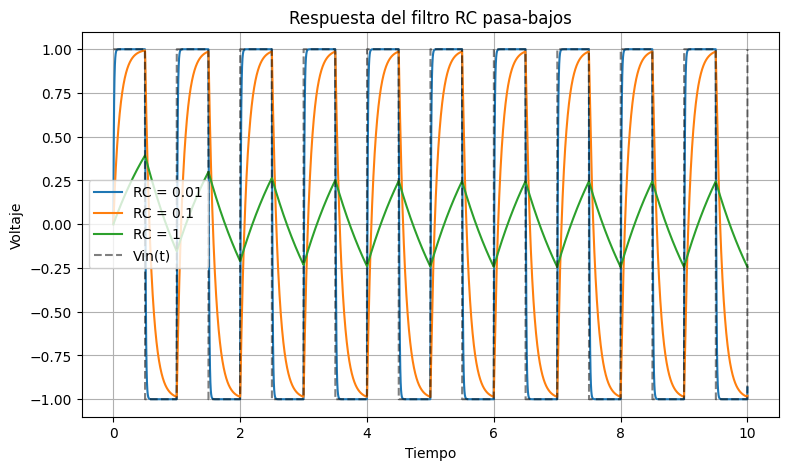

In [ ]:

#ejercicio 2

def Vin(t):
    if int(np.floor(2*t)) % 2 == 0:
        return 1.0
    else:
        return -1.0

#ecuacion diferencial
def f(t, Vout, RC):
    return (Vin(t) - Vout) / RC

#metodo RK4
def rk4(f, t, V0, RC):
    V = np.zeros(len(t))
    V[0] = V0

    for i in range(len(t)-1):
        h = t[i+1] - t[i]

        k1 = f(t[i], V[i], RC)
        k2 = f(t[i] + h/2, V[i] + h*k1/2, RC)
        k3 = f(t[i] + h/2, V[i] + h*k2/2, RC)
        k4 = f(t[i] + h, V[i] + h*k3, RC)

        V[i+1] = V[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return V
t = np.linspace(0, 10, 5000)
V0 = 0.0
RC_values = [0.01, 0.1, 1]

plt.figure(figsize=(9, 5))

for RC in RC_values:
    Vout = rk4(f, t, V0, RC)
    plt.plot(t, Vout, label=f'RC = {RC}')

# Señal de entrada
Vin_signal = np.array([Vin(ti) for ti in t])
plt.plot(t, Vin_signal, 'k--', alpha=0.5, label='Vin(t)')
plt.xlabel('Tiempo')
plt.ylabel('Voltaje')
plt.title('Respuesta del filtro RC pasa-bajos')
plt.legend()
plt.grid(True)
plt.show()

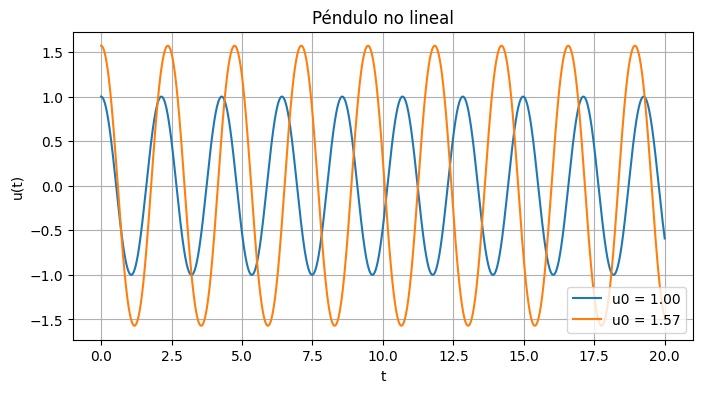

/tmp/ipython-input-1275644609.py:56: RuntimeWarning: divide by zero encountered in divide
  return np.sum(dz / np.sqrt((1 - z**2)*(1 - alpha*z**2)))


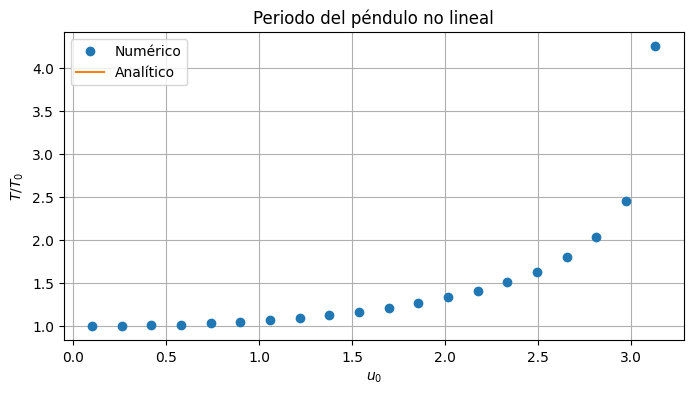

In [ ]:
#ejercicio 3
g = 9.81
l = 1.0
h = 0.001
t_max = 20
t = np.arange(0, t_max, h)

# ----------------------------------
# Sistema de ecuaciones
# y[0] = u, y[1] = du/dt
# ----------------------------------
def f(t, y):
    u, v = y
    du = v
    dv = -(g/l) * np.sin(u)
    return np.array([du, dv])

# ----------------------------------
# Runge-Kutta 4
# ----------------------------------
def rk4(f, t, y0):
    y = np.zeros((len(t), len(y0)))
    y[0] = y0

    for i in range(len(t)-1):
        k1 = f(t[i], y[i])
        k2 = f(t[i] + h/2, y[i] + h*k1/2)
        k3 = f(t[i] + h/2, y[i] + h*k2/2)
        k4 = f(t[i] + h, y[i] + h*k3)

        y[i+1] = y[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return y
u0_values = [1, np.pi/2]

plt.figure(figsize=(8,4))
for u0 in u0_values:
    sol = rk4(f, t, [u0, 0])
    plt.plot(t, sol[:,0], label=f'u0 = {u0:.2f}')

plt.xlabel('t')
plt.ylabel('u(t)')
plt.title('Péndulo no lineal')
plt.legend()
plt.grid()
plt.show()

def periodo_numerico(u, t):
    zeros = np.where(np.diff(np.sign(u)))[0]
    return 2*(t[zeros[1]] - t[zeros[0]])

# ----------------------------------
# Integral elíptica K(alpha)
def K(alpha, N=10000):
    z = np.linspace(0, 1, N)
    dz = z[1] - z[0]
    return np.sum(dz / np.sqrt((1 - z**2)*(1 - alpha*z**2)))

# ----------------------------------
# Comparación T/T0 vs u0
# ----------------------------------
T0 = 2*np.pi*np.sqrt(l/g)

u0_vals = np.linspace(0.1, np.pi-0.01, 20)
T_num = []
T_ana = []

for u0 in u0_vals:
    sol = rk4(f, t, [u0, 0])
    Tn = periodo_numerico(sol[:,0], t)
    T_num.append(Tn/T0)

    alpha = np.sin(u0/2)**2
    Ta = (2/np.pi) * K(alpha)
    T_ana.append(Ta)
plt.figure(figsize=(8,4))
plt.plot(u0_vals, T_num, 'o', label='Numérico')
plt.plot(u0_vals, T_ana, '-', label='Analítico')
plt.xlabel('$u_0$')
plt.ylabel('$T/T_0$')
plt.title('Periodo del péndulo no lineal')
plt.legend()
plt.grid()
plt.show()